# 01 — Exploration des données (GeoAI Mali)

Ce notebook **regarde** les données du projet avant tout calcul d'indice : que contient chaque couche, quelles sont ses valeurs typiques, où sont ses défauts.
Il ne recalcule rien : il lit les fichiers produits par les scripts de `src/` (voir `docs/METHODOLOGIE.md`, section 10, pour l'ordre d'exécution).

**À retenir en lisant** : la plupart des couches sont très asymétriques (beaucoup de petites valeurs, quelques très grandes). C'est ce qui justifie la normalisation par le rang dans le notebook 02.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio

# Racine du projet : le notebook peut être lancé depuis notebooks/ ou depuis la racine.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
PROC = ROOT / "data" / "processed"
OUT = ROOT / "outputs"
plt.rcParams["figure.dpi"] = 110


def load(name, folder=PROC):
    """Lit un raster (bande 1) en float, les valeurs « sans donnée » deviennent NaN."""
    with rasterio.open(folder / name) as src:
        arr = src.read(1).astype("float64")
        if src.nodata is not None:
            arr[arr == src.nodata] = np.nan
    return arr


def show(arr, title, cmap="viridis", vmin=None, vmax=None, ax=None):
    ax = ax or plt.gca()
    im = ax.imshow(arr, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()
    plt.colorbar(im, ax=ax, shrink=0.75)

## 1. Les fichiers attendus sont-ils là ?

In [2]:
expected = {
    "dem_bamako_utm.tif": "altitude (Copernicus DEM, 30 m, UTM 29N)",
    "slope_bamako_utm.tif": "pente en degrés",
    "dist_water_bamako_utm.tif": "distance au cours d'eau le plus proche (OSM)",
    "height_above_niger_utm.tif": "hauteur au-dessus du Niger",
    "twi_utm.tif": "indice d'humidité topographique",
    "built_fraction_utm.tif": "part de bâti (ESA WorldCover 2021)",
    "urban_mask_utm.tif": "masque des zones bâties",
    "flood_s1_count_utm.tif": "nombre de dates avec eau détectée par radar (0 à 5)",
    "susceptibility_bamako_utm.tif": "indice combiné",
}
rows = [{"fichier": f, "contenu": d, "présent": (PROC / f).exists()} for f, d in expected.items()]
pd.DataFrame(rows)

,fichier,contenu,présent
0,dem_bamako_utm.tif,"altitude (Copernicus DEM, 30 m, UTM 29N)",True
1,slope_bamako_utm.tif,pente en degrés,True
2,dist_water_bamako_utm.tif,distance au cours d'eau le plus proche (OSM),True
3,height_above_niger_utm.tif,hauteur au-dessus du Niger,True
4,twi_utm.tif,indice d'humidité topographique,True
5,built_fraction_utm.tif,part de bâti (ESA WorldCover 2021),True
6,urban_mask_utm.tif,masque des zones bâties,True
7,flood_s1_count_utm.tif,nombre de dates avec eau détectée par radar (0...,True
8,susceptibility_bamako_utm.tif,indice combiné,True


## 2. Relief : altitude et pente

Altitude : min 304 m, max 585 m | pente : médiane 2.0°, max 48°


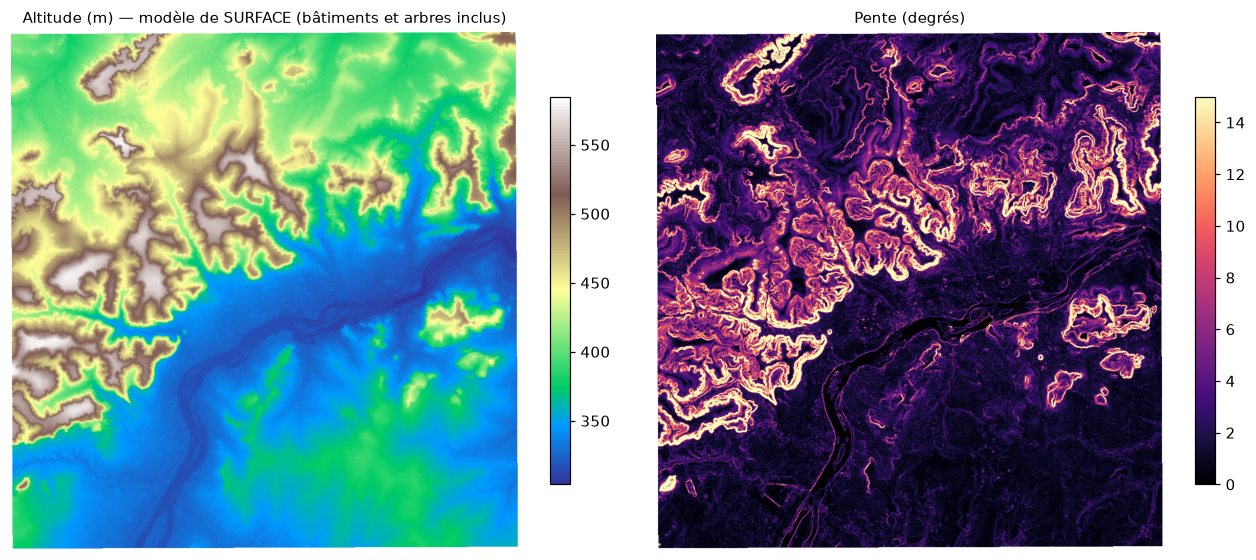

In [3]:
dem, slope = load("dem_bamako_utm.tif"), load("slope_bamako_utm.tif")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
show(dem, "Altitude (m) — modèle de SURFACE (bâtiments et arbres inclus)", "terrain", ax=axes[0])
show(slope, "Pente (degrés)", "magma", 0, 15, ax=axes[1])
plt.tight_layout()
print(f"Altitude : min {np.nanmin(dem):.0f} m, max {np.nanmax(dem):.0f} m | pente : médiane {np.nanmedian(slope):.1f}°, max {np.nanmax(slope):.0f}°")

**À noter.** La pente médiane est faible : la ville est sur un terrain plat, où une erreur d'altitude de 1 à 2 m (précision annoncée du modèle : RMSE ≈ 1,7 m) est du même ordre que les écarts entre quartiers. C'est la principale limite des critères de relief.

## 3. Eau : réseau OpenStreetMap et hauteur au-dessus du Niger

1042 segments de cours d'eau OSM, types :
kind
stream    446
drain     279
water     276
canal      25
river      16


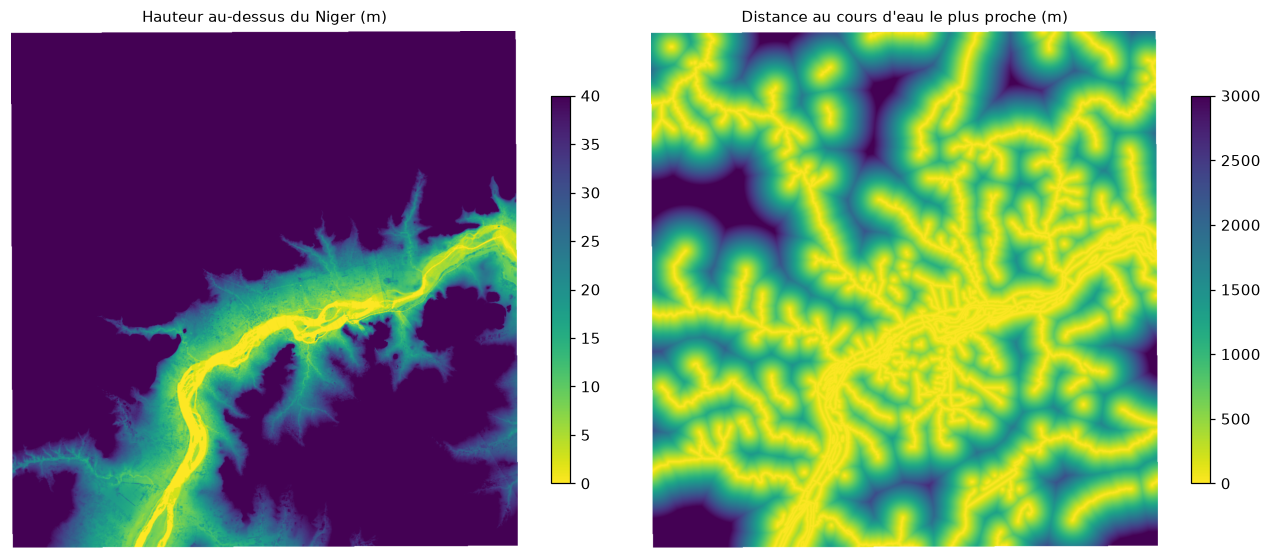

In [4]:
import geopandas as gpd

water = gpd.read_file(ROOT / "data" / "raw" / "osm_water_bamako.geojson")
print(f"{len(water)} segments de cours d'eau OSM, types :")
print(water["kind"].value_counts().to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
show(load("height_above_niger_utm.tif"), "Hauteur au-dessus du Niger (m)", "viridis_r", 0, 40, ax=axes[0])
show(load("dist_water_bamako_utm.tif"), "Distance au cours d'eau le plus proche (m)", "viridis_r", 0, 3000, ax=axes[1])
plt.tight_layout()

## 4. Convergence de l'eau : TWI

TWI : médiane 7.7


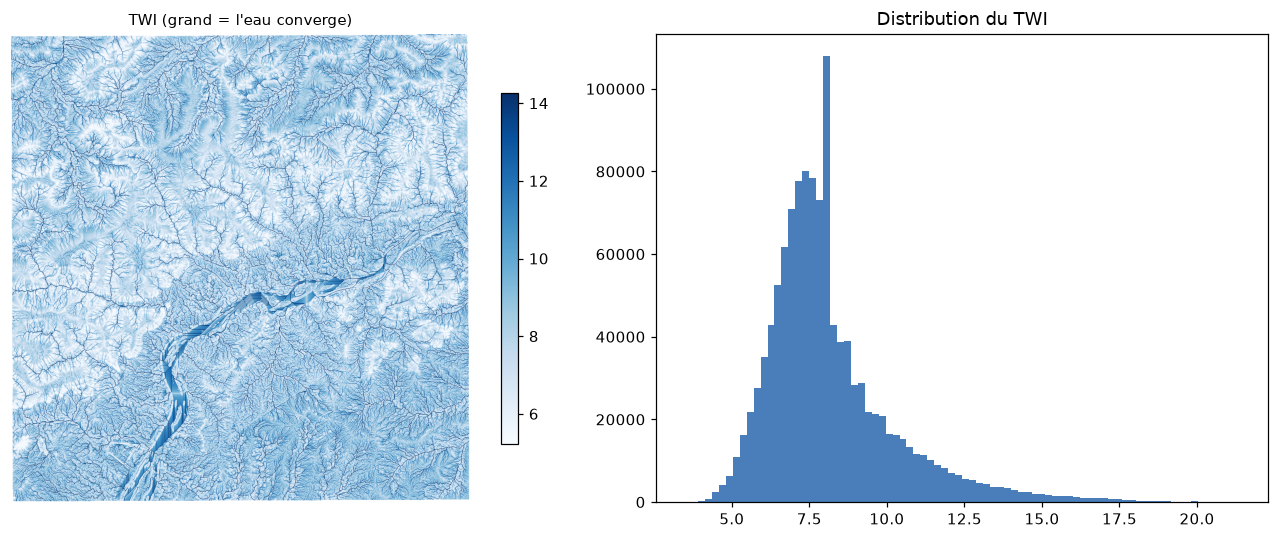

In [5]:
twi = load("twi_utm.tif")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
show(twi, "TWI (grand = l'eau converge)", "Blues", np.nanpercentile(twi, 2), np.nanpercentile(twi, 98), ax=axes[0])
axes[1].hist(twi[~np.isnan(twi)], bins=80, color="#4a7ebb")
axes[1].set_title("Distribution du TWI")
plt.tight_layout()
print(f"TWI : médiane {np.nanmedian(twi):.1f}")

**À noter.** Le TWI vient d'un modèle de surface : il est bruité en ville (toits, arbres). C'est le critère le plus fragile.

## 5. Des distributions très asymétriques

,hauteur (m),distance (m),pente (°),TWI
count,1200147.0,1200147.0,1196038.0,1196038.0
mean,84.2,884.9,3.7,8.2
std,62.5,818.8,4.5,2.1
min,-6.1,0.0,0.0,3.5
10%,14.0,84.9,0.6,6.1
50%,70.6,660.7,2.0,7.7
90%,177.9,2012.5,9.5,10.9
max,268.9,5447.1,48.0,21.4


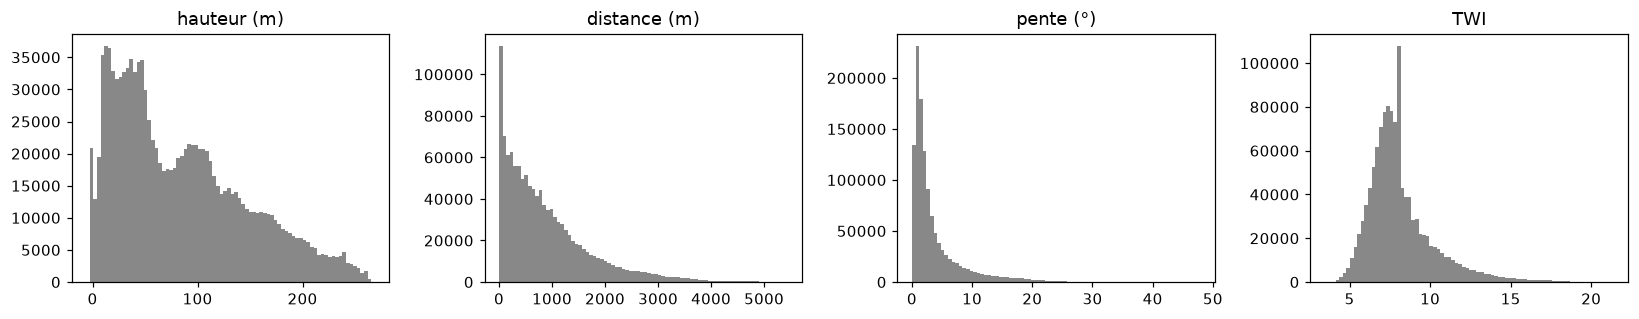

In [6]:
crit = {
    "hauteur (m)": load("height_above_niger_utm.tif"),
    "distance (m)": load("dist_water_bamako_utm.tif"),
    "pente (°)": slope,
    "TWI": twi,
}
fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, (name, arr) in zip(axes, crit.items()):
    v = arr[~np.isnan(arr)]
    ax.hist(v, bins=80, color="#888")
    ax.set_title(name)
plt.tight_layout()
pd.DataFrame({k: pd.Series(v[~np.isnan(v)]).describe(percentiles=[.1, .5, .9]) for k, v in crit.items()}).round(1)

**Pourquoi c'est important.** Une normalisation linéaire (min-max) écrase presque tout vers une même valeur quand la distribution est étirée. Le notebook 02 le montre : avec min-max, 60 % des pixels dépassaient 0,7. On normalise donc **par le rang** (percentile).

## 6. Occupation du sol : où est la ville ?

Zones bâties : 49 % de la zone d'étude


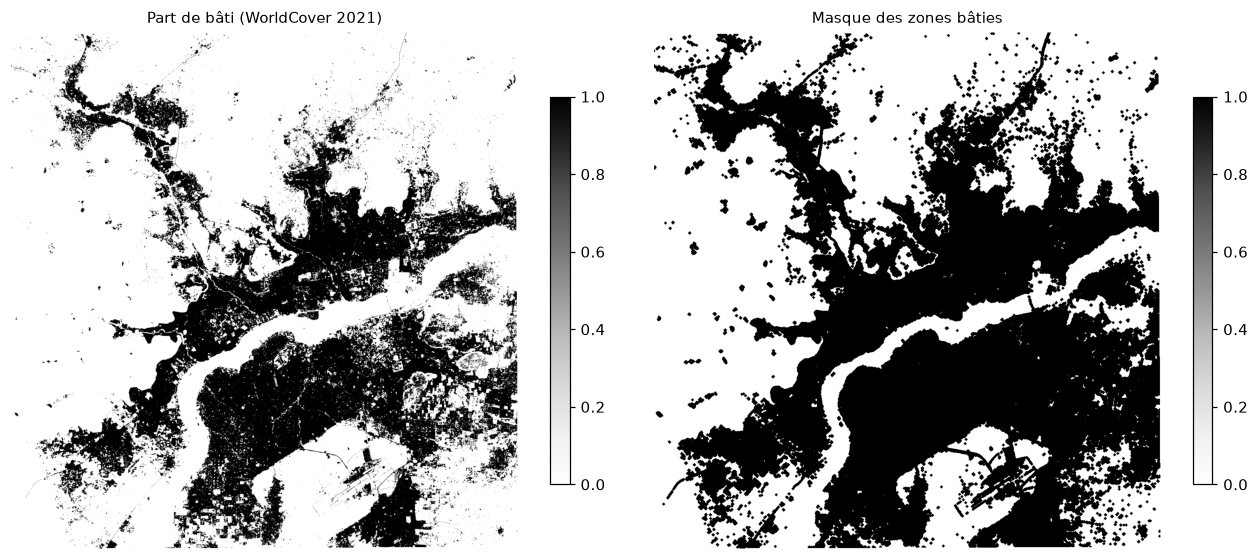

In [7]:
built, urban = load("built_fraction_utm.tif"), load("urban_mask_utm.tif")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
show(built, "Part de bâti (WorldCover 2021)", "Greys", 0, 1, ax=axes[0])
show(urban, "Masque des zones bâties", "Greys", 0, 1, ax=axes[1])
plt.tight_layout()
print(f"Zones bâties : {100 * np.nanmean(urban[~np.isnan(dem)] > 0):.0f} % de la zone d'étude")

## 7. Le radar : la même zone en saison sèche et en saison des pluies

Eau libre = surface lisse = écho radar faible (sombre, VV < -18 dB). Le fleuve est sombre toute l'année ;
l'eau « nouvelle » est ce qui devient sombre en saison des pluies (notebook 02).


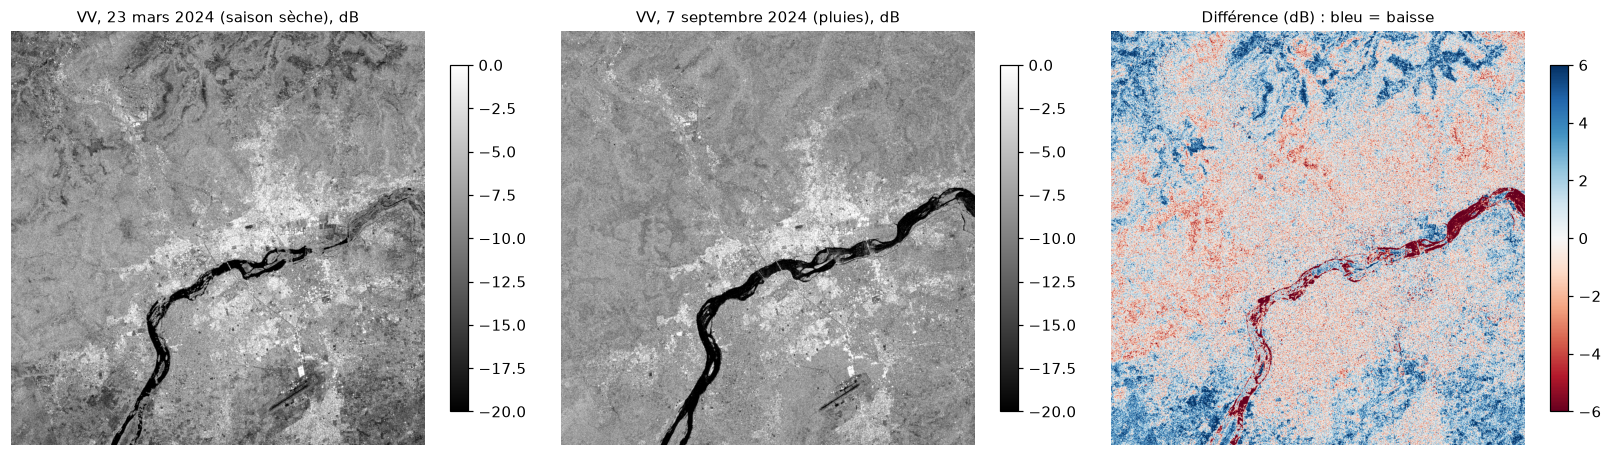

In [8]:
def vv_db(tag):
    path = ROOT / "data" / "raw" / "s1" / f"vv_{tag}.tif"
    with rasterio.open(path) as src:
        vv = src.read(1).astype("float64")
    return 10 * np.log10(np.where(vv > 0, vv, np.nan))

dry, wet = vv_db("20240323"), vv_db("20240907")
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
show(dry, "VV, 23 mars 2024 (saison sèche), dB", "gray", -20, 0, ax=axes[0])
show(wet, "VV, 7 septembre 2024 (pluies), dB", "gray", -20, 0, ax=axes[1])
show(wet - dry, "Différence (dB) : bleu = baisse", "RdBu", -6, 6, ax=axes[2])
plt.tight_layout()
print("Eau libre = surface lisse = écho radar faible (sombre, VV < -18 dB). Le fleuve est sombre toute l'année ;")
print("l'eau « nouvelle » est ce qui devient sombre en saison des pluies (notebook 02).")

## Ce que ce notebook montre

- Terrain plat, modèle de surface : les critères de relief sont imprécis, surtout en ville.
- Distributions étirées : normalisation par le rang plutôt que min-max.
- Réseau OSM et TWI : incomplet et bruité, à écrire dans les limites.
- Le radar voit bien le fleuve, beaucoup moins l'eau entre les bâtiments.